# Modelos por Género

Hökby et al. {cite}`hokby2025adolescents` encontraron, mediante un SEM multigrupo, que el tiempo de pantalla se asociaba con la depresión de forma directa en los chicos, mientras que en las chicas el efecto pasaba por la calidad, la duración y el cronotipo del sueño. Para contrastar ese hallazgo desde un enfoque predictivo, en este notebook se entrenan por separado para chicos y para chicas los dos modelos ganadores del modelo conjunto, CatBoost para `depressed` y ElasticNet para `bdi_total`, se comparan con el modelo conjunto en el test de cada grupo y se analiza qué factores pesan en cada uno.

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

pd.set_option("display.max_colwidth", None)

from Modelado import describir_espacio
from ModeladoRegresion import describir_espacio_reg
from Interpretabilidad import graficar_shap_beeswarm
from ModeladoGenero import (
    SEED, NOMBRES_GRUPO, PREDICTORES_GENERO, N_ITER_CATBOOST, N_ITER_ELASTICNET,
    preparar_grupos, tabla_tamanos,
    ajustar_catboost, elegir_umbral_grupo, ajustar_elasticnet, tabla_entrenamiento,
    cargar_modelos_conjuntos, evaluar_clasificacion_grupo, evaluar_regresion_grupo,
    vista_metricas, graficar_intervalos_grupos,
    explicar_grupo, graficar_barras_grupo, graficar_comparacion_grupos,
    importancias_largas, cargar_importancias_conjunto, tabla_ranking,
    guardar_resultados,
)

/opt/conda/envs/screen-time-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Datos: Split por Sexo

Se parte del mismo split de todo el modelado (`split_indices.csv`) y se filtran el train y el test por sexo, de modo que el test de cada grupo lo forman exactamente los adolescentes sobre los que ya se evaluó el modelo conjunto. Como `sex` es constante dentro de cada grupo, los modelos por género usan solo los cinco predictores numéricos, estandarizados con un `StandardScaler` dentro del Pipeline.

In [2]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

grupos = preparar_grupos(df)
tamanos = tabla_tamanos(grupos)

print(f"Predictores: {', '.join(PREDICTORES_GENERO)}")
tamanos

Predictores: sleep_quality_index, avg_sleep_hours, midsleep_weekend_hours, social_jetlag_hours, screen_time_index


Filas  Deprimidos  Prevalencia  BDI medio
Grupo  Conjunto                                           
Chicos Train      1957         168        0.086       5.29
       Test        489          42        0.086       4.94
Chicas Train      1891         462        0.244       9.38
       Test        473         115        0.243       9.44

La prevalencia de depresión es casi tres veces mayor en chicas (0.244 en train y 0.243 en test) que en chicos (0.086 en ambos conjuntos), y el BDI medio también es más alto en ellas (9.38 frente a 5.29 en train). Como consecuencia, el test de chicos tiene solo 42 positivos, frente a 115 en el de chicas, y sus métricas de clasificación son inestables: cada acierto o error mueve de forma apreciable la PR-AUC, el recall y la precision, y sus intervalos bootstrap son amplios.

## 1. Entrenamiento por Grupo

En cada grupo se repite el procedimiento del modelo conjunto usando solo su train. El CatBoost mantiene la estrategia nativa, sin balanceo, y se ajusta con `RandomizedSearchCV` sobre el mismo espacio de búsqueda, con 25 combinaciones, `StratifiedKFold(5, shuffle=True, random_state=SEED)` y la PR-AUC como métrica; entrena en CPU con `boosting_type="Plain"` y `thread_count=-1`, por lo que la búsqueda usa `n_jobs=1`. Su umbral de tamizaje se elige con las probabilidades *out-of-fold* del train del grupo, como la mayor precision que conserva un recall de al menos 0.70, el mismo criterio del modelo conjunto, sin recurrir nunca al test. El ElasticNet se ajusta con target nativo, 10 combinaciones, `KFold(5, shuffle=True, random_state=SEED)` y el RMSE como métrica, y sus predicciones se recortan al rango del BDI-II, [0, 63]. En ambos casos, el mejor Pipeline queda reentrenado con todo el train del grupo.

In [3]:
display(describir_espacio("catboost").style.set_caption(f"CatBoost: {N_ITER_CATBOOST} combinaciones por grupo"))
display(describir_espacio_reg("elasticnet").style.set_caption(f"ElasticNet: {N_ITER_ELASTICNET} combinaciones por grupo"))

,Valores
Hiperparámetro,
iterations,entero entre 200 y 800
depth,entero entre 3 y 7
learning_rate,log-uniforme entre 0.01 y 0.2
l2_leaf_reg,uniforme entre 1 y 10


,Valores
Hiperparámetro,
alpha,log-uniforme entre 0.0001 y 10
l1_ratio,uniforme entre 0.1 y 0.9


In [4]:
resultados = {}
for grupo, datos in grupos.items():
    catboost = ajustar_catboost(datos["X_train"], datos["y_dep_train"], seed=SEED)
    umbral = elegir_umbral_grupo(catboost["pipeline"], datos["X_train"], datos["y_dep_train"], seed=SEED)
    elasticnet = ajustar_elasticnet(datos["X_train"], datos["y_bdi_train"], seed=SEED)
    resultados[grupo] = {"catboost": catboost, "umbral": umbral, "elasticnet": elasticnet}
    print(f"✓ {NOMBRES_GRUPO[grupo]}")

tabla_entrenamiento(resultados).T

✓ Chicos
✓ Chicas


Grupo,Chicos,Chicas
CatBoost: hiperparámetros,"depth=3, iterations=356, l2_leaf_reg=8.22, learning_rate=0.0125","depth=3, iterations=356, l2_leaf_reg=8.22, learning_rate=0.0125"
CatBoost: PR-AUC de CV,0.221 ± 0.063,0.455 ± 0.069
Umbral de tamizaje,0.078,0.196
Precision OOF,0.142,0.343
Recall OOF,0.714,0.706
ElasticNet: hiperparámetros,"alpha=0.1013, l1_ratio=0.6665","alpha=0.1013, l1_ratio=0.6665"
ElasticNet: RMSE de CV,5.565 ± 0.178,8.065 ± 0.418


Los dos grupos eligieron la misma configuración, ya que la búsqueda evalúa las mismas 25 y 10 combinaciones en ambos: un CatBoost con `depth=3`, `iterations=356`, `l2_leaf_reg=8.22` y `learning_rate=0.0125`, y un ElasticNet con `alpha=0.1013` y `l1_ratio=0.6665`. Frente al modelo conjunto (`depth=4`, `l2_leaf_reg=1.572`, `learning_rate=0.02539`; `alpha=0.01445`, `l1_ratio=0.333`), los modelos por grupo usan árboles menos profundos, una regularización L2 mayor y una tasa de aprendizaje menor, y el ElasticNet aplica una penalización unas siete veces más fuerte y con más peso de L1.

La PR-AUC de CV es de 0.221 ± 0.063 en chicos y de 0.455 ± 0.069 en chicas, y el RMSE de CV, de 5.565 ± 0.178 y 8.065 ± 0.418 puntos BDI, respectivamente; ninguna de las dos diferencias es comparable directamente entre grupos, porque dependen de la prevalencia y de la dispersión del BDI de cada uno. El umbral de tamizaje refleja esas prevalencias distintas: en chicos baja a 0.078, con una precision *out-of-fold* de 0.142 y un recall de 0.714, mientras que en chicas sube a 0.196, con una precision de 0.343 y un recall de 0.706, a ambos lados del 0.153 del modelo conjunto.

## 2. Evaluación en Test

En el test de cada grupo se evalúan, una única vez, dos enfoques: el modelo específico entrenado con el train del grupo, con su propio umbral, y el modelo conjunto ya guardado, que se aplica sin reentrenar solo a los adolescentes del grupo y con su umbral de 0.153. En clasificación se reportan la PR-AUC, la línea base del grupo (su prevalencia en el test), la PR-AUC relativa a esa línea base, la ROC-AUC y el recall, la precision y el F1 con el umbral de cada enfoque; en regresión, el RMSE, el MAE y el R². La PR-AUC, la ROC-AUC, el RMSE y el R² se acompañan de su intervalo bootstrap al 95%, obtenido con 1000 réplicas del test del grupo que comparten los dos enfoques.

La PR-AUC no es comparable directamente entre chicos y chicas, porque su valor de referencia, el de un modelo que ordena al azar, es la prevalencia del grupo, y una misma capacidad de ordenar los casos produce una PR-AUC más alta donde la prevalencia es mayor. Por eso la comparación entre grupos se apoya en la ROC-AUC, que no depende de la prevalencia, y en la PR-AUC relativa, que indica cuántas veces supera el modelo a la línea base de su grupo. Dentro de un mismo grupo, en cambio, la PR-AUC sí permite comparar directamente el modelo específico con el conjunto.

In [5]:
conjuntos = cargar_modelos_conjuntos()
UMBRAL_CONJUNTO = conjuntos["umbral"]

pd.Series({
    "Clasificación": f"{conjuntos['metadatos_clf']['nombre']} (estrategia {conjuntos['metadatos_clf']['estrategia_balanceo']})",
    "Umbral de tamizaje": round(UMBRAL_CONJUNTO, 3),
    "Regresión": f"{conjuntos['metadatos_reg']['nombre']} (target {conjuntos['metadatos_reg']['variante_target']})",
}, name="Modelo conjunto").to_frame()

,Modelo conjunto
Clasificación,CatBoost (estrategia nativo)
Umbral de tamizaje,0.153
Regresión,ElasticNet (target nativo)


In [6]:
partes = []
for grupo, datos in grupos.items():
    res = resultados[grupo]
    probas = {
        "especifico": res["catboost"]["pipeline"].predict_proba(datos["X_test"])[:, 1],
        "conjunto": conjuntos["clasificador"].predict_proba(datos["X_test_conjunto"])[:, 1],
    }
    umbrales = {"especifico": res["umbral"]["umbral"], "conjunto": UMBRAL_CONJUNTO}
    predicciones = {
        "especifico": res["elasticnet"]["pipeline"].predict(datos["X_test"]),
        "conjunto": conjuntos["regresor"].predict(datos["X_test_conjunto"]),
    }
    partes.append(evaluar_clasificacion_grupo(grupo, datos["y_dep_test"], probas, umbrales, seed=SEED))
    partes.append(evaluar_regresion_grupo(grupo, datos["y_bdi_test"], predicciones, seed=SEED))

metricas_test = pd.concat(partes, ignore_index=True)

### Clasificación (`depressed`)

In [7]:
# Entre corchetes, el intervalo bootstrap al 95%
vista_metricas(metricas_test, "clasificacion")

PR-AUC Línea base PR-AUC relativa  \
Grupo  Enfoque                                                              
Chicos Modelo específico  0.386 [0.250, 0.529]      0.086           4.498   
       Modelo conjunto    0.402 [0.263, 0.548]      0.086           4.679   
Chicas Modelo específico  0.447 [0.375, 0.550]      0.243           1.837   
       Modelo conjunto    0.445 [0.371, 0.545]      0.243           1.830   

                                       ROC-AUC Umbral Recall Precision     F1  
Grupo  Enfoque                                                                 
Chicos Modelo específico  0.836 [0.769, 0.900]  0.078  0.857     0.187  0.306  
       Modelo conjunto    0.832 [0.766, 0.894]  0.153  0.524     0.400  0.454  
Chicas Modelo específico  0.727 [0.677, 0.779]  0.196  0.791     0.351  0.487  
       Modelo conjunto    0.725 [0.676, 0.777]  0.153  0.887     0.308  0.457

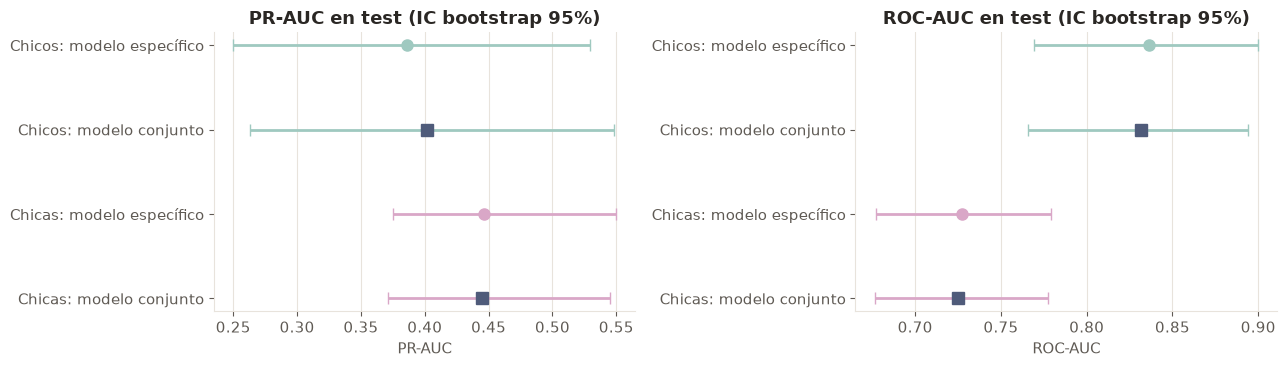

In [8]:
fig = graficar_intervalos_grupos(metricas_test, "clasificacion", ["PR-AUC", "ROC-AUC"])
plt.show()

En la gráfica, el color indica el grupo y el marcador el enfoque: un círculo en el color del grupo para el modelo específico y un cuadrado gris para el conjunto.

El modelo específico no supera al conjunto en ningún grupo. En chicos, la PR-AUC es de 0.386 (IC 95%: 0.250–0.529) con el específico y de 0.402 (0.263–0.548) con el conjunto, y la ROC-AUC, de 0.836 (0.769–0.900) y 0.832 (0.766–0.894); en chicas, la PR-AUC es de 0.447 (0.375–0.550) y 0.445 (0.371–0.545), y la ROC-AUC, de 0.727 (0.677–0.779) y 0.725 (0.676–0.777). Los intervalos de ambos enfoques se superponen casi por completo, y los de los chicos son más amplios que los de las chicas, como se anticipaba por sus 42 positivos.

Entre grupos, el modelo discrimina mejor en chicos. Su ROC-AUC (0.836) supera en algo más de 0.1 a la de las chicas (0.727), con intervalos que apenas se superponen, y su PR-AUC es 4.498 veces la línea base (0.086), frente a 1.837 veces en chicas (0.243). Aunque la PR-AUC bruta sea menor en chicos, el modelo ordena mejor sus casos respecto al azar.

La diferencia práctica entre enfoques está en el umbral. Con el 0.153 del modelo conjunto, en chicos solo se detecta el 52.4% de los casos (recall de 0.524, precision de 0.400, F1 de 0.454), muy por debajo del objetivo de 0.70; el umbral específico de 0.078 eleva el recall a 0.857 a costa de bajar la precision a 0.187 (F1 de 0.306). En chicas ocurre lo contrario: el umbral conjunto da un recall de 0.887 con una precision de 0.308 (F1 de 0.457), y el específico de 0.196 sacrifica recall (0.791) para ganar precision (0.351, F1 de 0.487). Un único umbral para todos resulta exigente para los chicos y permisivo para las chicas.

### Regresión (`bdi_total`)

In [9]:
vista_metricas(metricas_test, "regresion")

RMSE    MAE                    R²
Grupo  Enfoque                                                             
Chicos Modelo específico  5.204 [4.583, 5.855]  3.683  0.173 [0.093, 0.235]
       Modelo conjunto    5.214 [4.616, 5.862]  3.696  0.170 [0.063, 0.246]
Chicas Modelo específico  7.768 [6.989, 8.550]  5.800  0.151 [0.085, 0.218]
       Modelo conjunto    7.769 [6.984, 8.555]  5.791  0.151 [0.087, 0.217]

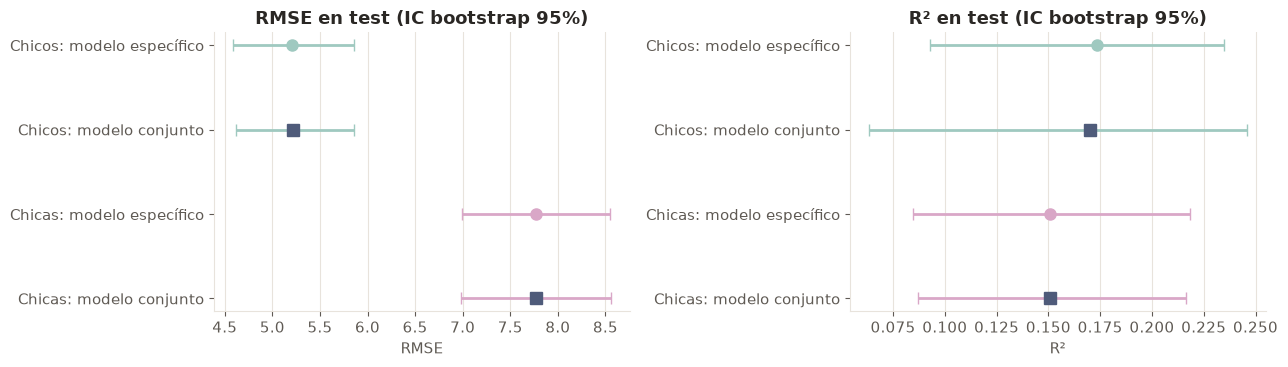

In [10]:
fig = graficar_intervalos_grupos(metricas_test, "regresion", ["RMSE", "R²"])
plt.show()

El RMSE se mide en puntos BDI y depende de la dispersión del BDI de cada grupo, mayor en chicas, por lo que para comparar los grupos es más informativo el R², la proporción de la varianza del BDI que explica el modelo.

En regresión, los dos enfoques son prácticamente idénticos. En chicos, el ElasticNet específico obtiene un RMSE de 5.204 (IC 95%: 4.583–5.855), un MAE de 3.683 y un R² de 0.173 (0.093–0.235), frente a 5.214 (4.616–5.862), 3.696 y 0.170 (0.063–0.246) del conjunto; en chicas, 7.768 (6.989–8.550), 5.800 y 0.151 (0.085–0.218) frente a 7.769 (6.984–8.555), 5.791 y 0.151 (0.087–0.217). A diferencia de la clasificación, el modelo explica una proporción de varianza similar en ambos grupos (0.173 en chicos y 0.151 en chicas), con intervalos que se superponen ampliamente.

## 3. Interpretabilidad por Género

La interpretabilidad se calcula con los modelos específicos de cada grupo y sobre su test, reutilizando las funciones del notebook de interpretabilidad del modelo conjunto, de modo que tablas y gráficos usan nombres legibles y los valores originales de las variables. En el ElasticNet, cada coeficiente expresa el cambio en puntos BDI por desviación estándar del predictor, con las demás variables fijas; la desviación estándar es la del train de cada grupo, y se indican los coeficientes que la penalización L1 llevó a cero. En el CatBoost se calculan la importancia nativa `PredictionValuesChange`, normalizada para sumar 100, y los valores SHAP de `shap.TreeExplainer`, en escala log-odds.

In [11]:
explicaciones = {
    grupo: explicar_grupo(
        resultados[grupo]["catboost"]["pipeline"], resultados[grupo]["elasticnet"]["pipeline"],
        grupos[grupo]["X_test"], grupos[grupo]["y_dep_test"],
    )
    for grupo in grupos
}

### Coeficientes del ElasticNet

In [12]:
columnas = ["Coeficiente (por DE)", "DE del train", "Efecto por unidad original", "Unidad", "En cero (L1)"]
display(pd.concat(
    {NOMBRES_GRUPO[grupo]: exp["coeficientes"][columnas] for grupo, exp in explicaciones.items()}, names=["Grupo"],
).round(3))

pd.DataFrame({
    "Intercepto (puntos BDI)": {NOMBRES_GRUPO[g]: round(exp["intercepto"], 2) for g, exp in explicaciones.items()},
    "Coeficientes en cero": {
        NOMBRES_GRUPO[g]: ", ".join(exp["coeficientes"].index[exp["coeficientes"]["En cero (L1)"]]) or "ninguno"
        for g, exp in explicaciones.items()
    },
})

Coeficiente (por DE)  \
Grupo  Variable                                                      
Chicos Índice de calidad del sueño                           1.506   
       Horas de sueño promedio                              -0.723   
       Índice de tiempo de pantalla                          0.420   
       Punto medio del sueño (fin de semana)                 0.224   
       Jet lag social                                        0.000   
Chicas Índice de calidad del sueño                           2.485   
       Horas de sueño promedio                              -1.007   
       Punto medio del sueño (fin de semana)                 0.554   
       Índice de tiempo de pantalla                          0.349   
       Jet lag social                                        0.000   

                                              DE del train  \
Grupo  Variable                                              
Chicos Índice de calidad del sueño                   0.717   
       Horas de sueño promedio                       1.212   
       Índice de tiempo de pantalla                  1.037   
       Punto medio del sueño (fin de semana)         1.413   
       Jet lag social                                1.162   
Chicas Índice de calidad del sueño                   0.941   
       Horas de sueño promedio                       1.310   
       Punto medio del sueño (fin de semana)         1.377   
       Índice de tiempo de pantalla                  1.010   
       Jet lag social                                1.095   

                                              Efecto por unidad original  \
Grupo  Variable                                                            
Chicos Índice de calidad del sueño                                 2.100   
       Horas de sueño promedio                                    -0.597   
       Índice de tiempo de pantalla                                0.405   
       Punto medio del sueño (fin de semana)                       0.159   
       Jet lag social                                              0.000   
Chicas Índice de calidad del sueño                                 2.641   
       Horas de sueño promedio                                    -0.769   
       Punto medio del sueño (fin de semana)                       0.402   
       Índice de tiempo de pantalla                                0.346   
       Jet lag social                                              0.000   

                                                        Unidad  En cero (L1)  
Grupo  Variable                                                               
Chicos Índice de calidad del sueño            punto del índice         False  
       Horas de sueño promedio                            hora         False  
       Índice de tiempo de pantalla           punto del índice         False  
       Punto medio del sueño (fin de semana)              hora         False  
       Jet lag social                                     hora          True  
Chicas Índice de calidad del sueño            punto del índice         False  
       Horas de sueño promedio                            hora         False  
       Punto medio del sueño (fin de semana)              hora         False  
       Índice de tiempo de pantalla           punto del índice         False  
       Jet lag social                                     hora          True

,Intercepto (puntos BDI),Coeficientes en cero
Chicos,5.29,Jet lag social
Chicas,9.38,Jet lag social


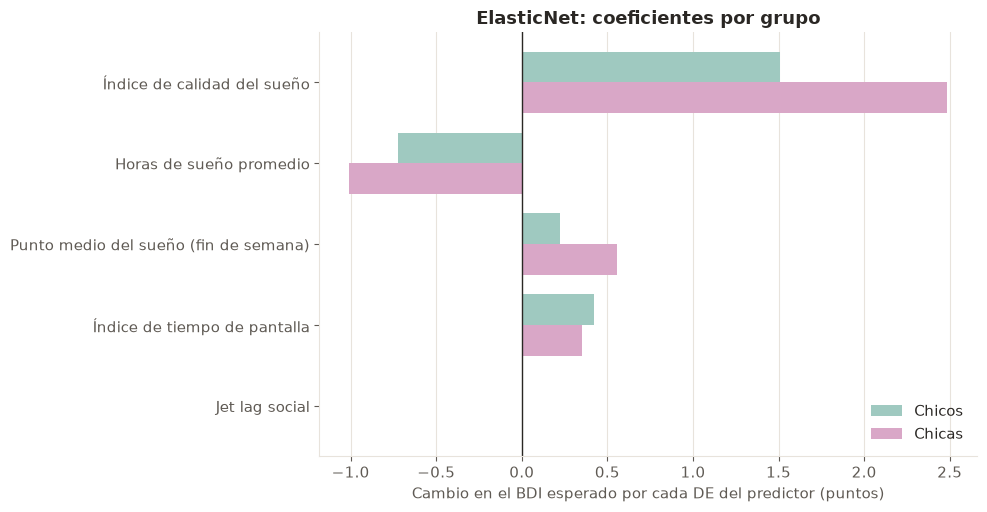

In [13]:
fig = graficar_comparacion_grupos(
    {grupo: exp["coeficientes"]["Coeficiente (por DE)"] for grupo, exp in explicaciones.items()},
    "ElasticNet: coeficientes por grupo", "Cambio en el BDI esperado por cada DE del predictor (puntos)",
)
plt.show()

Los coeficientes conservan el mismo signo en los dos grupos y la penalización L1 anula el jet lag social en ambos. La calidad del sueño es el predictor dominante, con 1.506 puntos BDI por desviación estándar en chicos y 2.485 en chicas (2.100 y 2.641 puntos por punto del índice), seguida de las horas de sueño, que reducen el BDI en 0.723 y 1.007 puntos por desviación estándar (0.597 y 0.769 puntos por hora adicional). Todos los efectos del sueño son mayores en chicas, incluido el punto medio del sueño del fin de semana (0.554 frente a 0.224). El tiempo de pantalla sigue el patrón inverso: su coeficiente es algo mayor en chicos (0.420 frente a 0.349 por desviación estándar), donde ocupa el tercer lugar, por delante del punto medio del sueño, mientras que en chicas queda en el cuarto. Los interceptos, 5.29 y 9.38 puntos BDI, recogen la diferencia de nivel entre grupos.

### Importancia Nativa del CatBoost

,Chicos,Chicas
Variable,,
Horas de sueño promedio,21.845,20.202
Jet lag social,8.298,8.973
Punto medio del sueño (fin de semana),15.187,11.853
Índice de calidad del sueño,41.652,52.269
Índice de tiempo de pantalla,13.018,6.703


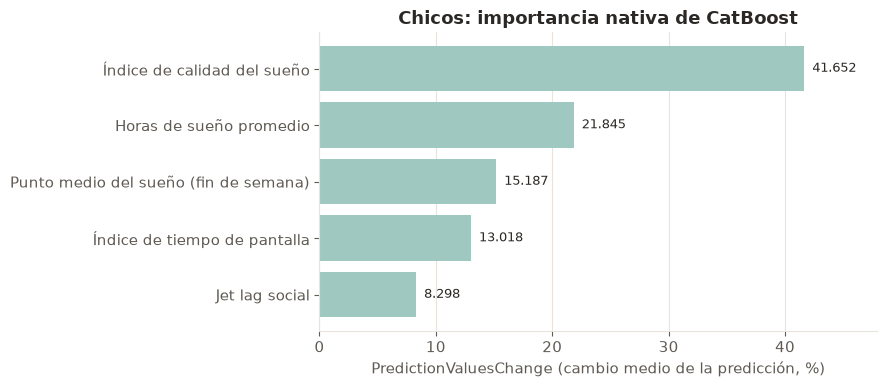

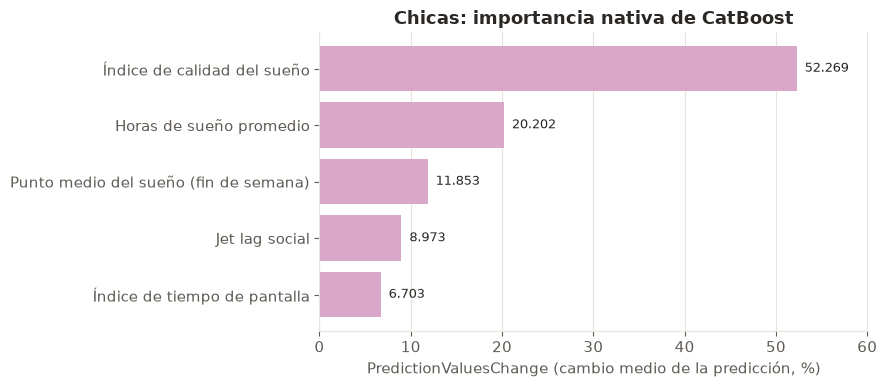

In [14]:
display(pd.DataFrame({NOMBRES_GRUPO[g]: exp["prediction_values_change"] for g, exp in explicaciones.items()}).round(3))

for grupo, exp in explicaciones.items():
    fig = graficar_barras_grupo(
        exp["prediction_values_change"], grupo, f"{NOMBRES_GRUPO[grupo]}: importancia nativa de CatBoost",
        "PredictionValuesChange (cambio medio de la predicción, %)",
    )
    plt.show()

La importancia nativa coincide en las dos primeras variables: la calidad del sueño concentra el 41.652% de la importancia en chicos y el 52.269% en chicas, y las horas de sueño, el 21.845% y el 20.202%. La diferencia más clara está en el tiempo de pantalla, cuya importancia en chicos (13.018) casi duplica la de las chicas (6.703), lo que lo sitúa en el cuarto lugar en ellos y en el último en ellas, por detrás del jet lag social (8.973).

### SHAP del CatBoost

La media de |SHAP| resume el efecto típico de cada variable en log-odds de depresión. En el beeswarm, cada punto es un adolescente del test del grupo: su posición horizontal es el valor SHAP y su color, el valor original de la variable, de modo que si los puntos rojos quedan a la derecha, los valores altos de la variable aumentan el riesgo.

,Chicos,Chicas
Horas de sueño promedio,0.2231,0.1778
Jet lag social,0.0392,0.0483
Punto medio del sueño (fin de semana),0.1415,0.0936
Índice de calidad del sueño,0.3213,0.4126
Índice de tiempo de pantalla,0.1405,0.0379


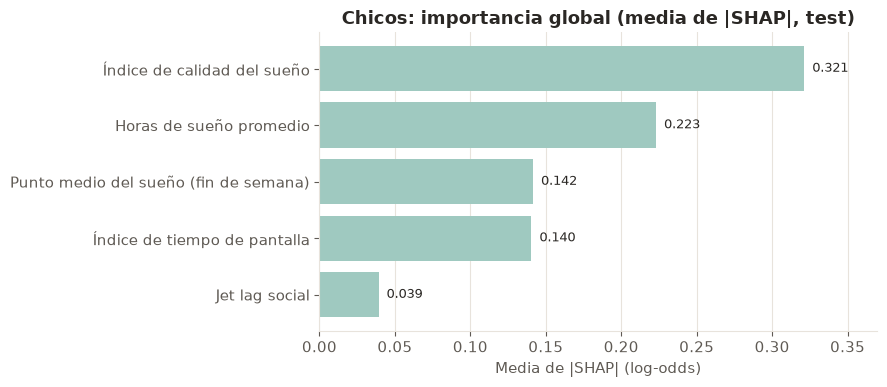

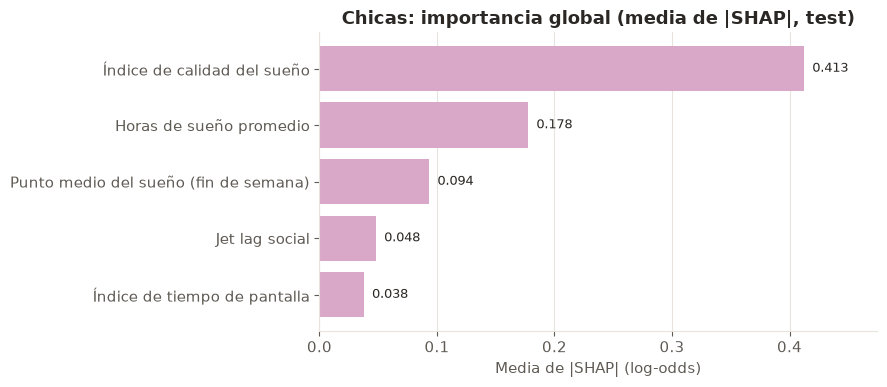

In [15]:
display(pd.DataFrame({NOMBRES_GRUPO[g]: exp["shap_global"] for g, exp in explicaciones.items()}).round(4))

for grupo, exp in explicaciones.items():
    fig = graficar_barras_grupo(
        exp["shap_global"], grupo, f"{NOMBRES_GRUPO[grupo]}: importancia global (media de |SHAP|, test)",
        "Media de |SHAP| (log-odds)",
    )
    plt.show()

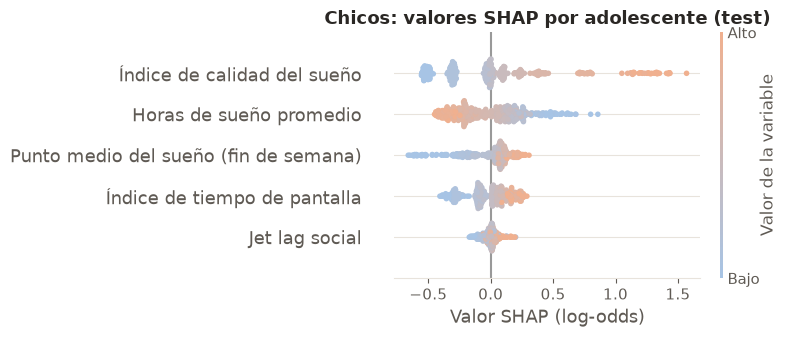

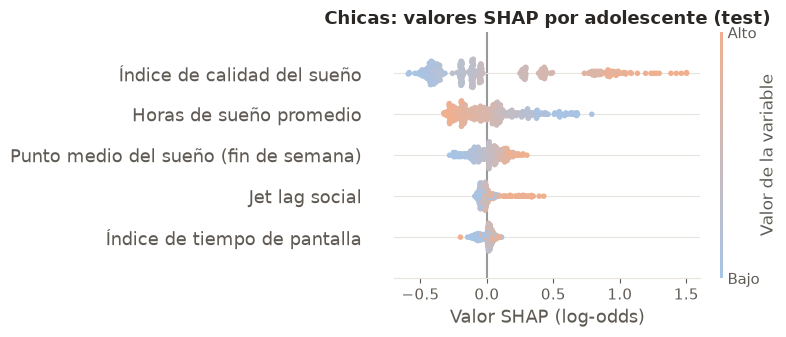

In [16]:
for grupo, exp in explicaciones.items():
    fig = graficar_shap_beeswarm(exp["shap"], f"{NOMBRES_GRUPO[grupo]}: valores SHAP por adolescente (test)", "log-odds")
    plt.show()

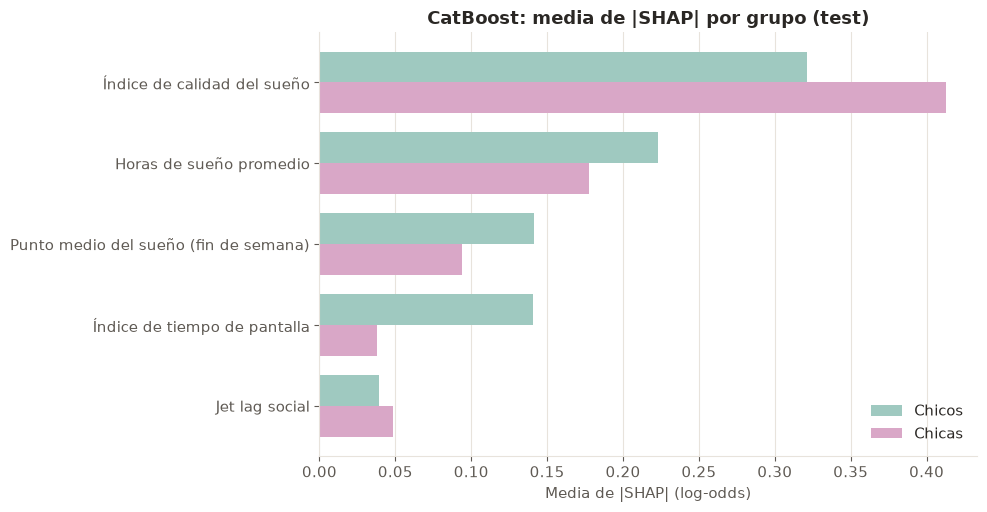

In [17]:
fig = graficar_comparacion_grupos(
    {grupo: exp["shap_global"] for grupo, exp in explicaciones.items()},
    "CatBoost: media de |SHAP| por grupo (test)", "Media de |SHAP| (log-odds)",
)
plt.show()

SHAP confirma el patrón de la importancia nativa. La calidad del sueño tiene la mayor contribución media en ambos grupos, 0.3213 log-odds en chicos y 0.4126 en chicas, seguida de las horas de sueño (0.2231 y 0.1778). En chicos, el tiempo de pantalla (0.1405) prácticamente empata con el punto medio del sueño (0.1415), mientras que en chicas su contribución cae a 0.0379, casi cuatro veces menos, y queda en el último lugar.

Los beeswarm muestran que ningún efecto cambia de dirección entre grupos. En ambos, una peor calidad del sueño aumenta el riesgo, con contribuciones de hasta cerca de +1.5 log-odds, dormir menos lo incrementa y un punto medio del sueño más tardío lo eleva levemente. El tiempo de pantalla mantiene también su dirección, pero su recorrido difiere: en chicos sus valores SHAP se extienden aproximadamente de −0.4 a +0.25 log-odds, mientras que en chicas se concentran en torno a cero. En las chicas, en cambio, el jet lag social muestra una cola positiva de hasta cerca de +0.4 log-odds en sus valores altos.

### Ranking de Variables

La tabla recoge el puesto de cada variable, donde 1 corresponde a la más importante, según cada método en el modelo conjunto, en chicos y en chicas. Los coeficientes se ordenan por su valor absoluto. Los valores del modelo conjunto provienen de `data/processed/modelado/interpretabilidad/importancias.csv`, del que se excluye `sex` para que los tres rankings incluyan las mismas cinco variables.

In [18]:
importancias = importancias_largas(explicaciones)
importancias_conjunto = cargar_importancias_conjunto()

tabla_ranking(importancias, importancias_conjunto)

Conjunto  \
Método                             Variable                                          
Coeficientes (ElasticNet, |coef.|) Índice de calidad del sueño                   1   
                                   Horas de sueño promedio                       2   
                                   Índice de tiempo de pantalla                  3   
                                   Punto medio del sueño (fin de semana)         4   
                                   Jet lag social                                5   
Importancia nativa (CatBoost)      Índice de calidad del sueño                   1   
                                   Horas de sueño promedio                       2   
                                   Punto medio del sueño (fin de semana)         3   
                                   Jet lag social                                4   
                                   Índice de tiempo de pantalla                  5   
Media de |SHAP| (CatBoost)         Índice de calidad del sueño                   1   
                                   Horas de sueño promedio                       2   
                                   Punto medio del sueño (fin de semana)         3   
                                   Índice de tiempo de pantalla                  4   
                                   Jet lag social                                5   

                                                                          Chicos  \
Método                             Variable                                        
Coeficientes (ElasticNet, |coef.|) Índice de calidad del sueño                 1   
                                   Horas de sueño promedio                     2   
                                   Índice de tiempo de pantalla                3   
                                   Punto medio del sueño (fin de semana)       4   
                                   Jet lag social                              5   
Importancia nativa (CatBoost)      Índice de calidad del sueño                 1   
                                   Horas de sueño promedio                     2   
                                   Punto medio del sueño (fin de semana)       3   
                                   Jet lag social                              5   
                                   Índice de tiempo de pantalla                4   
Media de |SHAP| (CatBoost)         Índice de calidad del sueño                 1   
                                   Horas de sueño promedio                     2   
                                   Punto medio del sueño (fin de semana)       3   
                                   Índice de tiempo de pantalla                4   
                                   Jet lag social                              5   

                                                                          Chicas  
Método                             Variable                                       
Coeficientes (ElasticNet, |coef.|) Índice de calidad del sueño                 1  
                                   Horas de sueño promedio                     2  
                                   Índice de tiempo de pantalla                4  
                                   Punto medio del sueño (fin de semana)       3  
                                   Jet lag social                              5  
Importancia nativa (CatBoost)      Índice de calidad del sueño                 1  
                                   Horas de sueño promedio                     2  
                                   Punto medio del sueño (fin de semana)       3  
                                   Jet lag social                              4  
                                   Índice de tiempo de pantalla                5  
Media de |SHAP| (CatBoost)         Índice de calidad del sueño                 1  
                                   Horas de sueño promedio                     2  
                    

La calidad del sueño ocupa el primer puesto y las horas de sueño el segundo en los tres métodos y en los tres modelos. Las diferencias se limitan a los puestos inferiores y giran en torno al tiempo de pantalla. En chicos coincide con el modelo conjunto en coeficientes y SHAP, y en la importancia nativa sube al cuarto puesto, por delante del jet lag social. En chicas ocurre lo contrario: baja al cuarto puesto en los coeficientes, por detrás del punto medio del sueño, y al quinto en SHAP, por detrás del jet lag social.

## Conclusiones

El sueño domina la predicción en ambos grupos. La calidad del sueño es la variable más importante en chicos y en chicas según los tres métodos, seguida siempre de las horas de sueño, y su peso es mayor en las chicas, tanto en los coeficientes (2.485 frente a 1.506 puntos BDI por desviación estándar) como en SHAP (0.4126 frente a 0.3213 log-odds). El tiempo de pantalla, en cambio, pesa más en los chicos, sobre todo en CatBoost, donde su contribución media en SHAP (0.1405) es casi cuatro veces la de las chicas (0.0379) y su importancia nativa casi el doble (13.018 frente a 6.703); en el ElasticNet la diferencia es menor (0.420 frente a 0.349). Ningún efecto cambia de dirección entre grupos.

Este patrón es coherente con el enfoque multigrupo de Hökby et al. {cite}`hokby2025adolescents`: en las chicas, la información predictiva se concentra en las variables del sueño y el tiempo de pantalla apenas añade algo propio, mientras que en los chicos conserva una contribución independiente del sueño, compatible con el efecto directo que ellos reportaron. Conviene recordar, sin embargo, que estas importancias son predictivas y no estiman efectos de mediación. Además, los modelos específicos no mejoran al conjunto en ningún grupo, por lo que entrenar por separado aporta interpretación pero no desempeño, salvo en la elección del umbral.

El test de chicos cuenta solo con 42 positivos, de modo que las diferencias pequeñas entre grupos, tanto en las métricas como en el orden de las variables de menor importancia, pueden deberse al ruido de muestreo y no a una diferencia real entre chicos y chicas.

### Guardado

In [19]:
metadatos = guardar_resultados(resultados, metricas_test, importancias, tamanos)

✓ Guardado en /workspace/data/processed/modelado/genero: modelos/, metricas_test.csv, importancias.csv y metadatos.json
